# HW4: predicting 90-day stock returns and trading on them

Quentin Benchetrit

Every week I score about 1,800 liquid US stocks with a regression that forecasts the part of each stock's 90-day return that its market beta does not explain. I buy the ten best names at the last close of the week and hold each purchase for 90 calendar days. The model, the entry screens and the trading rules were fixed on 2010-2015 data, and the test from April 2016 to September 2026 was then run once.

**Result.** The strategy did not beat the S&P 500 total-return index. $1,000,000 grew to $2.68M against $4.40M for the index, 9.9% a year against 15.2%. It carried two thirds of the market's risk (beta 0.66, volatility 14% against 18%) but its Sharpe ratio was lower too, 0.60 against 0.77. Sections 7 and 8 explain the gap and what I would change.

In [1]:
import subprocess
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator

from hw4.backtest import Backtester, WeeklyTopN, benchmark_nav, market_exposure, performance
from hw4.data import find_database, load_fundamentals, load_market, load_membership
from hw4.features import FEATURES, build_panel, weekly_schedule
from hw4.model import (PRIOR_SIGNS, RISK_FEATURES, ReturnModel, boosted_trees, forecast_report,
                       quarter_ends, ridge, shrunk_beta, training_rows, walk_forward)

warnings.filterwarnings("ignore", category=RuntimeWarning)   # logs and ratios of missing prices
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

database = find_database()
market = load_market(database)
fundamentals = load_fundamentals(database)
membership = load_membership(database)
market.audit

{'off_calendar_rows': 27,
 'non_positive_adj_close_rows': 0,
 'isolated_spike_rows': 362,
 'symbols_with_spikes': 19,
 'forfeited_one_day_gains': 1691}

## 1. What the file can and cannot support

Three properties of the data decide how far a backtest on it can be trusted, so I looked at them before modelling.

**Stocks that died before 2021 are mostly absent.** The table below counts symbols by the year of their last quote. Only 44 stop before 2021, against more than a thousand between 2021 and 2025. A company delisted between 2010 and 2020 is simply not in the file, so the development sample and the first half of the test are close to survivor-only. That flatters anything that buys distressed or very volatile names in those years, and it weighed on my choice of model.

In [2]:
last_quote = market.adj_close.apply(pd.Series.last_valid_index).dropna()
ended = last_quote[last_quote < market.calendar[-1]]
ended.dt.year.value_counts().sort_index().rename("symbols whose quotes end").to_frame().T

,2010,2014,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
symbols whose quotes end,1,1,13,17,9,2,1,111,210,233,243,276,217


**Prices are on today's split basis.** `close` is adjusted for splits that happened later: NVDA shows $0.46 in January 2010. The vendor's share counts are on the same basis for the names I checked (AAPL, NVDA), so close x shares still gives a sensible market value. Two consequences. A price floor such as "above $5" would select on future splits, so I never filter on the price level. And liquidity is measured in dollars traded (close x volume), which no split can distort.

**Some corporate actions are missing from `adj_close`.** Level 3 (LVLT) did a 1-for-15 reverse split on 20 October 2011 and the adjusted series jumps from 1.55 to 23.10 that day. A lot held through it would book a fake fifteen-fold gain. When loading prices I give up every one-day gain above 100% by rescaling the later prices, real or not, which removes 1,691 daily returns since 2008. Earlier prices are untouched, so nothing dated *t* changes when later data arrives. One-day drops are left as they are: a missed forward split then shows up as a fake loss, the conservative side to err on. I also remove 362 quotes from 19 tickers whose series flip between two price levels from one day to the next. This filter compares each quote with the next one, so it looks one session ahead; none of these 19 symbols is bought in the test.

In [3]:
days = slice("2011-10-18", "2011-10-21")
pd.DataFrame({"vendor adj_close": market.raw_adj_close.loc[days, "LVLT"],
              "series I trade on": market.adj_close.loc[days, "LVLT"]})

,vendor adj_close,series I trade on
date,,
2011-10-18,1.650,1.650
2011-10-19,1.550,1.550
2011-10-20,23.100,1.550
2011-10-21,23.500,1.577


## 2. Signals, features and target

**Timing.** A signal uses data up to the close of day *t*. The order is filled at the close of the next session, and the target is the return from that fill to the first close on or after the 90th calendar day. Signals are taken on the second-to-last session of each week so that entries fall on the last one. A lot bought on a Friday matures on a Thursday; it is sold at that close and its cash is known in time for the order placed that evening.

**Features.** Each one is converted to its rank among the stocks that can be bought that day, which removes outliers and unit problems without fitting anything on history.

| Group | Features |
|---|---|
| Momentum | 6- and 12-month return skipping the last month, distance to the 52-week high, last month's return |
| Risk | 63- and 252-day volatility, idiosyncratic volatility, beta, largest daily gain of the month |
| Profitability | ROA, ROE, gross profit / assets, operating margin, asset turnover, accruals |
| Change | acceleration of revenue growth, year-on-year change in net income and in gross margin, asset growth, share issuance |
| Value | earnings, book, sales, operating cash flow and free cash flow over market value, EBITDA / EV |

Sixteen more (short-horizon returns, liquidity, size, leverage, R&D, filing age) are computed as well and only serve the unconstrained models of section 3.

Statements come from quarterly rows whose filing date is after the fiscal date, and become usable the day after filing. Trailing-year sums need four consecutive quarters, year-on-year changes need the quarter of a year earlier, and a statement is dropped once its fiscal period is more than a year old.

**Who can be bought.** A stock is a candidate on day *t* if it is in the top-2,000 list of the quarter in which the entry falls, was quoted and traded on at least 60 of the last 63 sessions, has a median daily dollar volume of at least $1M, and had no one-day move beyond a factor of 2 in the past year (glitches and broken stocks). Two more screens remove stocks that have stopped moving: a median absolute daily return under 0.25% over 21 sessions, or a 21-day volatility below 35% of the 252-day figure. They are aimed at cash-merger targets pinned under their offer price and at blank-check shells. Their upside is capped, and when they leave the file nothing says what a holder received. The 35% cut-off is the 0.5th percentile of that ratio in 2010-2015. I checked the mechanism on the prices of the few names that leave the file in 2016-2018 (CPGX, LLTC, TE sit between 0.10 and 0.18 a month before their last quote), without looking at any strategy result.

The $1M floor matters more than it looks: in 2010 a third of the listed "top 2,000" trades less than that, because the names that should fill those ranks died before 2021 and are missing.

In [4]:
panel = build_panel(market, fundamentals, membership)
panel.to_parquet(OUT / "panel.parquet", index=False)

by_year = panel.groupby(panel.date.dt.year).agg(
    signal_dates=("date", "nunique"), members=("symbol", "size"),
    eligible=("eligible", "sum"), with_outcome=("target", "count"))
by_year["eligible_per_date"] = (by_year.eligible / by_year.signal_dates).round().astype(int)
by_year.T

date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
signal_dates,52,52,52,52,53,52,52,52,52,52,53,52,52,52,52,53,38
members,99802,103335,104000,104000,106000,104000,104000,104000,104000,104000,106000,104000,104000,104000,104000,106000,76000
eligible,65801,71132,70773,77245,88147,91974,92534,95400,97566,97439,97728,95405,96597,97027,97575,99892,71767
with_outcome,99518,103091,103839,103932,105932,103957,103741,103677,103850,103862,105877,102811,101849,102034,101907,103452,50553
eligible_per_date,1265,1368,1361,1485,1663,1769,1780,1835,1876,1874,1844,1835,1858,1866,1876,1885,1889


One label recomputed from the raw table, to check the alignment: signal on Thursday 12 June 2014, entry at the Friday close, exit 90 days later on Thursday 11 September.

In [5]:
row = panel[(panel.symbol == "MSFT") & (panel.date == "2014-06-12")].iloc[0]
with duckdb.connect(str(database), read_only=True) as con:
    msft = con.execute("SELECT date, adj_close FROM prices WHERE symbol = 'MSFT' "
                       "AND date IN ('2014-06-13', '2014-09-11')").fetchdf()
by_hand = msft.adj_close.iloc[1] / msft.adj_close.iloc[0] - 1
print(msft.to_string(index=False))
print(f"panel: entry {row.entry_date.date()}, exit {row.label_end.date()}, target {row.target:.6f}; "
      f"by hand {by_hand:.6f}")
assert np.isclose(row.target, by_hand)

      date  adj_close
2014-06-13     34.570
2014-09-11     39.650
panel: entry 2014-06-13, exit 2014-09-11, target 0.146948; by hand 0.146948


## 3. Development, 2010-2015

### 3.1 Model

Every candidate goes through the same walk-forward: refit at the end of each quarter from December 2011 to September 2015 on all rows since 2010 whose exit date is already past, then score the following quarter. That gives four years of out-of-sample forecasts. Outcomes that end after the buffer are blanked so nothing later than March 2016 can enter.

The columns are the average rank correlation between forecast and realised return, and the average 90-day return of the 50 highest forecasts minus the index over the same window, with the beta of those 50 names.

In [6]:
DEV_END, BUFFER_END = "2015-12-31", "2016-03-31"
dev = panel[panel.date <= DEV_END].copy()
dev.loc[dev.label_end > BUFFER_END, ["target", "benchmark_target", "label_end"]] = np.nan
dev_fits = quarter_ends(market.calendar, "2011-12-01", "2015-09-30")


class EqualWeights(BaseEstimator):
    # Reference point: average the signed ranks, estimate nothing.
    def fit(self, X, y):
        return self

    def predict(self, X):
        return np.nan_to_num(X).mean(axis=1)


class WithMarketTerm(ReturnModel):
    # Forecast of the full return: alpha plus beta times the average index move seen in training.
    def fit(self, rows):
        self.market_ = rows.groupby("date").benchmark_target.first().mean()
        return super().fit(rows)

    def predict(self, rows):
        return super().predict(rows) + shrunk_beta(rows) * self.market_


signed = list(PRIOR_SIGNS)
no_risk = [f for f in signed if f not in RISK_FEATURES]
candidates = {
    "ridge, all 42 features": ReturnModel(ridge(), FEATURES, target="median"),
    "boosted trees, all 42 features": ReturnModel(boosted_trees(), FEATURES, target="median"),
    "signed ridge, median target": ReturnModel(ridge(positive=True), signed, PRIOR_SIGNS, "median"),
    "signed ridge, alpha target": ReturnModel(ridge(positive=True), signed, PRIOR_SIGNS, "alpha"),
    "  same, without risk features": ReturnModel(ridge(positive=True), no_risk, PRIOR_SIGNS, "alpha"),
    "  same, plus beta x mean index return": WithMarketTerm(ridge(positive=True), signed, PRIOR_SIGNS, "alpha"),
    "  same, refit once a year": ReturnModel(ridge(positive=True), signed, PRIOR_SIGNS, "alpha"),
    "monotone trees, alpha target": ReturnModel(
        boosted_trees(monotone=[1] * len(signed), max_depth=2, learning_rate=0.03, max_iter=150,
                      min_samples_leaf=1000), signed, PRIOR_SIGNS, "alpha"),
    "equal weights, nothing fitted": ReturnModel(EqualWeights(), signed, PRIOR_SIGNS, "alpha"),
}
dev_predictions, rows = {}, {}
for name, model in candidates.items():
    fits = dev_fits[::4] if "once a year" in name else dev_fits
    dev_predictions[name], _ = walk_forward(dev, model, fits, DEV_END)
    rows[name] = forecast_report(dev_predictions[name], dev)
dev_models = pd.DataFrame(rows).T
dev_models.to_csv(OUT / "dev_models.csv")
dev_models

,rank_ic,ic_2012,ic_2013,ic_2014,ic_2015,top50_vs_index,vs_index_2012,vs_index_2013,vs_index_2014,vs_index_2015,top50_beta
"ridge, all 42 features",0.024,0.045,0.018,-0.010,0.042,0.008,0.037,0.042,-0.019,-0.029,1.359
"boosted trees, all 42 features",0.001,-0.010,0.021,-0.030,0.022,-0.011,-0.001,0.038,-0.015,-0.068,1.400
"signed ridge, median target",0.031,0.005,0.047,0.002,0.071,0.003,0.009,0.030,-0.010,-0.016,1.105
"signed ridge, alpha target",0.043,-0.006,-0.018,0.056,0.141,0.002,0.006,0.004,0.002,-0.007,0.794
"same, without risk features",0.040,-0.010,0.034,0.015,0.121,0.003,0.006,0.032,-0.011,-0.014,1.059
"same, plus beta x mean index return",0.041,0.025,0.038,0.002,0.099,0.002,0.015,0.032,-0.022,-0.017,1.515
"same, refit once a year",0.047,0.005,-0.029,0.068,0.142,0.003,0.004,0.002,0.011,-0.005,0.814
"monotone trees, alpha target",0.031,-0.012,-0.048,0.050,0.134,0.003,0.006,0.013,0.007,-0.015,0.882
"equal weights, nothing fitted",0.055,0.021,-0.020,0.083,0.134,0.003,0.010,0.009,0.001,-0.008,0.840


What I take from this table:

- The two unconstrained models on all features look good in 2012-2013 (their top 50 beat the index by about 4% a quarter in 2013) and give it all back in 2014-2015. The names they pick have a beta near 1.4. They learned the 2012-2013 rally in volatile stocks, which in a survivor-only file never ends in a delisting.
- Fixing the sign of every coefficient to the direction reported in the literature (momentum up, risk down, profitability up, issuance down, cheapness up) and letting the regression choose only the sizes gives a positive rank correlation in each of the four years.
- "Return minus the median stock" still contains a market bet, because high-beta names beat the median whenever the index rises: the sign of the volatility-return relation flips with the market year by year in this sample. Taking out beta x index return instead raises the rank correlation from 0.031 to 0.043, and the picks drop to a beta of 0.79. Without the risk features the beta stays near 1.06 and the rank correlation is 0.040.
- Adding back beta x the average index move gives a forecast of the full return, but it ranks stocks mostly by beta (1.52 for the top 50). I did not want the result to be a leveraged bet on the market.
- Monotone trees on the same inputs are no better. Plain equal weights on the signed ranks do about as well as the fitted regression, which says how little four years can tell about the size of each effect once its direction is fixed. I keep the regression because it can at least drop a characteristic that stops working.
- A yearly refit is as good as a quarterly one. I keep the quarterly refit because the candidate list changes every quarter anyway.

Four years of overlapping 90-day returns are about sixteen independent quarters, so none of these gaps is significant on its own. I chose on steadiness and on the reasoning above: **the sign-constrained ridge with the alpha target and the risk features**. Its top 50 stay within a point of the index in each of the four years, where the unconstrained models swing between +4% and -7% a quarter. I knew at that point that it would run with a beta well below 1.

### 3.2 Trading rules

The same forecasts are now traded with the backtester of section 4, from January 2012 to December 2015, under a few variants of the rules. "Random picks" uses the same rules with a random ranking, averaged over five seeds: it shows what the eligible universe earns without any model.

In [7]:
schedule = weekly_schedule(market.calendar)


def backtest(scores, start, end, fee_bps=10, orphan_recovery=None, **rules):
    strategy = WeeklyTopN(scores, schedule, market.sectors, **rules)
    return Backtester(market, strategy, fee_bps=fee_bps, orphan_recovery=orphan_recovery).run(start, end)


def summary(result):
    nav = result.history.nav
    index = benchmark_nav(market.benchmark, result.history)
    return pd.concat([performance(nav), market_exposure(nav, index)])


def random_picks(scores, start, end, seeds=5, **rules):
    runs = []
    for seed in range(seeds):
        noise = np.random.default_rng(seed).random(len(scores))
        runs.append(summary(backtest(scores[["date", "symbol"]].assign(prediction=noise), start, end, **rules)))
    return pd.DataFrame(runs).mean()


FORMATS = {"final_value": "${:,.0f}", "cagr": "{:.2%}", "max_drawdown": "{:.1%}", "volatility": "{:.1%}",
           "sharpe": "{:.2f}", "beta": "{:.2f}", "alpha": "{:+.2%}"}


def formatted(table):
    return table.apply(lambda column: column.map(
        lambda value: "" if pd.isna(value) else FORMATS[column.name].format(value)))


DEV_START = "2012-01-03"
chosen = dev_predictions["signed ridge, alpha target"]
largest = chosen.merge(dev.loc[dev.universe_rank <= 1000, ["date", "symbol"]])
variants = {
    "10 names a week": dict(scores=chosen, n_names=10),
    "5 names a week": dict(scores=chosen, n_names=5),
    "20 names a week": dict(scores=chosen, n_names=20),
    "10 names, no caps": dict(scores=chosen, n_names=10, name_cap=1.0, sector_cap=1.0),
    "10 names, no costs": dict(scores=chosen, n_names=10, fee_bps=0),
    "10 names, 25 bps a side": dict(scores=chosen, n_names=10, fee_bps=25),
    "one cohort of 130 names per quarter": dict(scores=chosen, n_names=130, tranches=1),
    "10 names among the 1,000 largest": dict(scores=largest, n_names=10),
    "ridge on all features, 10 names": dict(scores=dev_predictions["ridge, all 42 features"], n_names=10),
    "boosted trees, 10 names": dict(scores=dev_predictions["boosted trees, all 42 features"], n_names=10),
}
rows = {name: summary(backtest(start=DEV_START, end=DEV_END, **settings)) for name, settings in variants.items()}
rows["random picks, 10 names"] = random_picks(chosen, DEV_START, DEV_END, n_names=10)
reference = backtest(chosen, DEV_START, DEV_END, n_names=10)
rows["S&P 500 TR"] = performance(benchmark_nav(market.benchmark, reference.history))
dev_backtests = pd.DataFrame(rows).T[["cagr", "max_drawdown", "volatility", "sharpe", "beta", "alpha"]]
dev_backtests.to_csv(OUT / "dev_backtests.csv")

after_ramp = reference.history.nav.loc["2012-04-05":]
index_after = market.benchmark.loc[after_ramp.index]
print(f"from the end of the ramp-up (5 April 2012): strategy {after_ramp.iloc[-1] / after_ramp.iloc[0] - 1:+.1%}, "
      f"index {index_after.iloc[-1] / index_after.iloc[0] - 1:+.1%}")
formatted(dev_backtests)

from the end of the ramp-up (5 April 2012): strategy +63.5%, index +58.3%


,cagr,max_drawdown,volatility,sharpe,beta,alpha
10 names a week,14.32%,-11.1%,11.7%,1.04,0.83,+1.60%
5 names a week,13.02%,-12.3%,11.8%,0.93,0.83,+0.43%
20 names a week,13.35%,-10.2%,11.5%,0.98,0.82,+0.76%
"10 names, no caps",12.83%,-13.2%,11.8%,0.92,0.82,+0.40%
"10 names, no costs",15.11%,-11.0%,11.7%,1.10,0.82,+2.29%
"10 names, 25 bps a side",12.94%,-11.6%,11.7%,0.94,0.82,+0.40%
one cohort of 130 names per quarter,13.22%,-11.6%,11.9%,0.94,0.86,+0.24%
"10 names among the 1,000 largest",13.13%,-12.0%,11.5%,0.96,0.82,+0.61%
"ridge on all features, 10 names",16.08%,-20.8%,18.8%,0.79,1.20,-0.53%
"boosted trees, 10 names",15.47%,-24.5%,21.3%,0.69,1.31,-2.01%


With ten names a week the strategy returns 14.3% a year against 14.9% for the index, with a slightly better Sharpe ratio (1.04 against 1.00) and drawdown, and it is well ahead of random picks (12.5%, Sharpe 0.75). The shortfall against the index comes from the first quarter: the book is built over thirteen weeks, and those weeks happened to be a +12.6% quarter for the index. Counted from the end of the ramp-up the strategy is ahead, +63.5% against +58.3%.

Five, ten or twenty names a week cannot be told apart, so I take ten, which gives about 130 lots of 0.8% each. The 3% name cap and 30% sector cap cost nothing here and I keep them. A single cohort of 130 names per quarter earns about the same, but it rests on four trading dates a year and on signals up to three months old, so I keep weekly tranches and accept the one-off cost of the ramp-up. Restricting to the 1,000 largest names does not help.

The two unconstrained models made more money than my choice over these four years (16.1% and 15.5% a year), with a beta of 1.2 to 1.3, twice the drawdown and a negative alpha. I did not consider that a reason to prefer them.

### 3.3 What is frozen before the test

In [8]:
MODEL = ReturnModel(ridge(alpha=1000, positive=True), list(PRIOR_SIGNS), PRIOR_SIGNS, target="alpha")
RULES = dict(n_names=10, tranches=13, name_cap=0.03, sector_cap=0.30)
FEE_BPS = 10
TEST_START, TEST_END = "2016-04-01", "2026-09-30"

weights = MODEL.fit(training_rows(dev, pd.Timestamp(BUFFER_END))).weights()
weights[weights != 0].sort_values().round(4).to_frame("coefficient at the first test fit").T

,beta,vol_63,vol_252,max_ret_21,share_growth,operating_margin,asset_turnover,margin_change,cash_flow_yield,high_252,income_change,sales_to_price,fcf_yield,mom_12_1,revenue_acceleration,gross_profitability
coefficient at the first test fit,-0.013,-0.011,-0.009,-0.008,-0.004,0.001,0.001,0.002,0.002,0.004,0.006,0.007,0.008,0.011,0.012,0.017


The update rule during the test is the one used above: refit at the last close of every quarter on all rows since 2010 whose exit is already past. The coefficients are in return per unit of rank: going from the bottom to the top of the momentum ranking adds about 1% to the forecast.

## 4. Backtester

`hw4/backtest.py` keeps cash, a list of open lots and a ledger of fills, and steps through the calendar one session at a time: read the closes, sell the lots that have matured, fill the orders decided at the previous close, record the state, then ask the strategy for tomorrow's orders. An order is a dollar amount fixed at the decision close, so the fill price is never known in advance and a budget can only come from cash that existed at that close.

My assumptions:

- **Costs.** 10 bps of traded value on each side, for commission, half-spread and impact. A lot is about $8,000 to $20,000, at most 2% of a day's volume at the $1M floor. The index pays nothing.
- **Cash** earns no interest.
- **Dividends.** Positions are fractional units of `adj_close`, so dividends are already in the returns and never added.
- **Missing prices.** An order that meets no quote on its entry day is dropped and the cash waits for the next week. A holding without a quote is carried at its last close. A matured lot is sold at the first quote on or after day 90. After 63 sessions without a quote the lot is treated as gone: the file has no delisting proceeds, so I book no sale. It stays in the portfolio at its last observed close and frees no cash. Section 7 brackets this with a total loss and with a payout at the last close.

The cases below are small enough to verify on paper; the expected values in `check_backtester.py` are written from the rules, not read back from the backtester.

In [9]:
print(subprocess.run([sys.executable, "check_backtester.py"], capture_output=True, text=True).stdout)

1. buy 100,000 of AAA at 50: 1998.0020 units, NAV after fees 999,820.18
2. AAA due Sunday 11 Apr, sold Monday 12 Apr for 119,760.24
3. BBB halted over maturity, marked at 21 and sold on 15 Apr for 54,890.11
4. CCC never quotes again: no fill, lot kept at 35,964.04, final NAV 1,030,614.39
5. order on a day without a quote is dropped, cash unchanged
6. CCC written off: 994,650.35; paid out at last close: 1,030,614.39
7. cash rebuilt from the fills ledger matches every day
8. overspending refused: 2021-01-08: orders must be positive and covered by cash
9. weekly tranches: 1/4 of NAV per week, name cap moves week 3 to the next five names

all checks passed



## 5. Final test, April 2016 to September 2026

The first model is fitted after the close of 31 March 2016 on outcomes that ended before that day, and scores that evening's signal for the first purchase on 1 April. The audit table shows the first two fits and the last one.

In [10]:
test_fits = quarter_ends(market.calendar, "2016-03-31", "2026-06-30")
predictions, fit_audit = walk_forward(panel, MODEL, test_fits, TEST_END)
assert (fit_audit.last_label_end < fit_audit.first_scored_signal).all()
predictions.to_parquet(OUT / "predictions.parquet", index=False)
fit_audit.to_csv(OUT / "fit_audit.csv", index=False)
fit_audit.iloc[[0, 1, -1]]

,fit_date,training_rows,first_training_signal,last_training_signal,last_label_end,first_scored_signal,last_scored_signal
0,2016-03-31,465024,2010-01-07,2015-12-30,2016-03-30,2016-03-31,2016-06-23
1,2016-06-30,486617,2010-01-07,2016-03-23,2016-06-22,2016-06-30,2016-09-29
41,2026-06-30,1451538,2010-01-07,2026-03-26,2026-06-25,2026-07-01,2026-09-24


In [11]:
result = backtest(predictions, TEST_START, TEST_END, fee_bps=FEE_BPS, **RULES)
history, fills = result.history, result.fills
index_nav = benchmark_nav(market.benchmark, history)

comparison = pd.DataFrame({"strategy": performance(history.nav), "S&P 500 TR": performance(index_nav)})
comparison.to_csv(OUT / "performance.csv")
history.assign(benchmark=index_nav).to_csv(OUT / "nav.csv")
fills.to_csv(OUT / "fills.csv", index=False)
result.open_lots.to_csv(OUT / "open_lots.csv", index=False)

shown = comparison.T
pd.DataFrame({"final value": shown.final_value.map("${:,.0f}".format),
              "CAGR": shown.cagr.map("{:.2%}".format),
              "max drawdown": shown.max_drawdown.map("{:.2%}".format),
              "Sharpe (rf 2%)": shown.sharpe.map("{:.2f}".format),
              "volatility": shown.volatility.map("{:.2%}".format)})

,final value,CAGR,max drawdown,Sharpe (rf 2%),volatility
strategy,"$2,682,735",9.85%,-31.57%,0.60,14.00%
S&P 500 TR,"$4,402,747",15.16%,-33.79%,0.77,17.82%


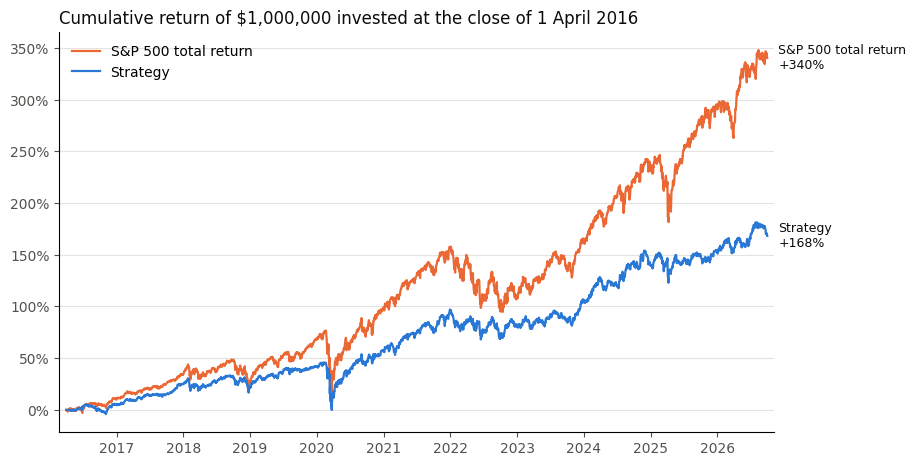

In [12]:
INK, MUTED = "#0b0b0b", "#52514e"
fig, ax = plt.subplots(figsize=(10, 5.2))
for nav, label, color in [(index_nav, "S&P 500 total return", "#eb6834"), (history.nav, "Strategy", "#2a78d6")]:
    cumulative = nav / 1_000_000 - 1
    ax.plot(cumulative.index, cumulative * 100, color=color, lw=1.6, label=label)
    ax.annotate(f"{label}\n{cumulative.iloc[-1]:+.0%}", (cumulative.index[-1], cumulative.iloc[-1] * 100),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_title("Cumulative return of $1,000,000 invested at the close of 1 April 2016", loc="left", color=INK)
ax.yaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="y", color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
ax.margins(x=0.01)
ax.legend(frameon=False, loc="upper left")
fig.subplots_adjust(right=0.84)
fig.savefig(OUT / "cumulative_returns.png", dpi=150)
plt.show()

In [13]:
def calendar_years(nav):
    year_end = nav.groupby(nav.index.year).last()
    return year_end.pct_change().fillna(year_end.iloc[0] / nav.iloc[0] - 1)


years = pd.DataFrame({"strategy": calendar_years(history.nav), "S&P 500 TR": calendar_years(index_nav)})
years["difference"] = years.strategy - years["S&P 500 TR"]
years = years.rename(index={2016: "2016 from April", 2026: "2026 to September"})
years.T.map("{:+.1%}".format)

date,2016 from April,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026 to September
strategy,+4.4%,+19.5%,-1.8%,+15.8%,+10.9%,+25.0%,-7.8%,+13.4%,+16.7%,+4.8%,+6.7%
S&P 500 TR,+9.8%,+21.8%,-4.4%,+31.5%,+18.4%,+28.7%,-18.1%,+26.3%,+25.0%,+17.9%,+12.7%
difference,-5.4%,-2.3%,+2.6%,-15.7%,-7.5%,-3.7%,+10.3%,-12.9%,-8.3%,-13.1%,-6.1%


The strategy ends at $2,682,735 and the index at $4,402,747: **the benchmark wins by $1.72M, or 5.3 points of annual return.** The strategy is ahead in the two down years, 2018 and 2022, and behind in every other one, most of all in 2019, 2023 and 2025.

## 6. Checks on the real run

The same identities as in the toy cases, on the 10,699 fills of the test, and a comparison of every sale with the raw price table.

In [14]:
buys = fills[fills.side == "BUY"].set_index("lot_id")
sells = fills[fills.side == "SELL"].set_index("lot_id")
open_lots = result.open_lots

# Cash never goes negative, is fully explained by the ledger, and NAV = cash + holdings.
rebuilt = 1_000_000 + fills.groupby("date").cash_change.sum().reindex(history.index).fillna(0).cumsum()
assert np.allclose(rebuilt, history.cash) and history.cash.min() > -1e-6
assert np.allclose(history.cash + history.holdings, history.nav)

# Realised plus unrealised P&L equals the change in NAV.
unrealised = (open_lots.units * open_lots.last_price - open_lots.cost).sum()
assert np.isclose(sells.pnl.sum() + unrealised, history.nav.iloc[-1] - 1_000_000)

# Every purchase was decided one session earlier, from a forecast made by a model
# fitted no later than that day on outcomes that had already ended.
session = market.calendar.get_indexer
assert (session(buys.date) - session(buys.signal_date) == 1).all()
used = (buys.reset_index()
        .merge(predictions, left_on=["signal_date", "symbol"], right_on=["date", "symbol"], suffixes=("", "_scored"))
        .merge(fit_audit[["fit_date", "last_label_end"]], on="fit_date"))
assert len(used) == len(buys)
assert (used.fit_date <= used.signal_date).all() and (used.last_label_end < used.signal_date).all()

# Nothing is sold before day 90 and nothing trades after the last day.
held = (sells.date - buys.date.reindex(sells.index)).dt.days
assert held.min() >= 90 and fills.date.max() <= pd.Timestamp(TEST_END)

print(f"{len(buys):,} purchases, {len(sells):,} sales, {len(open_lots)} lots open on {TEST_END}")
print(f"days held by sold lots: min {held.min()}, median {held.median():.0f}, max {held.max()}")
print(f"lowest cash balance ${round(history.cash.min(), 2) + 0.0:,.2f}, fees paid ${fills.fee.sum():,.0f}")
print(f"P&L: realised ${sells.pnl.sum():,.0f} + unrealised ${unrealised:,.0f} "
      f"= ${history.nav.iloc[-1] - 1_000_000:,.0f}")

5,423 purchases, 5,276 sales, 147 lots open on 2026-09-30
days held by sold lots: min 90, median 90, max 91
lowest cash balance $0.00, fees paid $136,022
P&L: realised $1,790,132 + unrealised $-107,397 = $1,682,735


In [15]:
# Independent look at the vendor table: when was each lot's first quote on or after day 90?
with duckdb.connect(str(database), read_only=True) as con:
    raw = con.execute("SELECT symbol, date AS quote_date, adj_close FROM prices "
                      "WHERE date BETWEEN ? AND ? AND adj_close > 0 ORDER BY date",
                      [TEST_START, TEST_END]).fetchdf()
    index_ends = con.execute("SELECT adj_close FROM benchmark WHERE date IN (?, ?) ORDER BY date",
                             [TEST_START, TEST_END]).fetchdf().adj_close
raw["quote_date"] = pd.to_datetime(raw.quote_date).astype("datetime64[ns]")

lots = buys.reset_index()[["lot_id", "symbol", "date", "due_date"]].sort_values("due_date")
first_quote = pd.merge_asof(lots, raw, left_on="due_date", right_on="quote_date",
                            by="symbol", direction="forward").set_index("lot_id").quote_date

on_time = first_quote.reindex(sells.index) == sells.date
left_open = first_quote.reindex(open_lots.lot_id)
not_due = open_lots.set_index("lot_id").due_date > pd.Timestamp(TEST_END)
print(f"sales made on the first raw quote on or after day 90: {on_time.sum():,} of {len(sells):,}")
print(f"open lots: {not_due.sum()} not yet due, {(~not_due & left_open.isna()).sum()} past due with no "
      f"later quote in the raw table, {(~not_due & left_open.notna()).sum()} other")

# Fill prices against the raw adjusted close of the same day.
raw_price = raw.set_index(["symbol", "quote_date"]).adj_close
paid = raw_price.reindex(pd.MultiIndex.from_frame(buys[["symbol", "date"]])).to_numpy()
received = raw_price.reindex(pd.MultiIndex.from_frame(sells[["symbol", "date"]])).to_numpy()
print(f"purchases at the raw adj_close: {np.isclose(buys.price, paid).sum():,} of {len(buys):,}; "
      f"sales: {np.isclose(sells.price, received).sum():,} of {len(sells):,}")
rescaled = sorted(set(buys.symbol[~np.isclose(buys.price, paid)]) | set(sells.symbol[~np.isclose(sells.price, received)]))
entry_raw = raw_price.reindex(pd.MultiIndex.from_frame(buys.loc[sells.index, ["symbol", "date"]])).to_numpy()
same_return = np.isclose(sells.price / buys.price.reindex(sells.index), received / entry_raw)
print("symbols traded on a series rescaled after an earlier one-day gain above 100%:", rescaled)
print(f"round trips whose return equals the raw series' return: {same_return.sum():,} of {len(sells):,}")

print(f"index: $1M x {index_ends.iloc[1]:,.2f} / {index_ends.iloc[0]:,.2f} = "
      f"${1e6 * index_ends.iloc[1] / index_ends.iloc[0]:,.0f}; NAV series ends at ${index_nav.iloc[-1]:,.0f}")

sales made on the first raw quote on or after day 90: 5,276 of 5,276
open lots: 125 not yet due, 22 past due with no later quote in the raw table, 0 other


purchases at the raw adj_close: 5,381 of 5,423; sales: 5,238 of 5,276
symbols traded on a series rescaled after an earlier one-day gain above 100%: ['CRC', 'CSW', 'EVC', 'EXPI', 'HIG', 'INDV', 'PARR', 'VG', 'WY']
round trips whose return equals the raw series' return: 5,276 of 5,276
index: $1M x 17,160.41 / 3,897.66 = $4,402,747; NAV series ends at $4,402,747


Three lots recomputed from the raw table: the first purchase of the test, the best and the worst round trip. Units are budget / (price x 1.001) and proceeds are units x price x 0.999.

In [16]:
def by_hand(lot_id):
    buy, sell = buys.loc[lot_id], sells.loc[lot_id]
    quotes = raw[raw.symbol == buy.symbol].set_index("quote_date").adj_close
    due = buy.date + pd.Timedelta(days=90)
    exit_date = quotes.index[quotes.index >= due][0]
    units = -buy.cash_change / (quotes[buy.date] * 1.001)
    proceeds = units * quotes[exit_date] * 0.999
    assert exit_date == sell.date and np.isclose(units, buy.units) and np.isclose(proceeds, sell.cash_change)
    return {"symbol": buy.symbol, "signal": buy.signal_date.date(), "entry": buy.date.date(),
            "budget": -buy.cash_change, "entry price": quotes[buy.date], "units": units,
            "day 90": f"{due.date()} ({due.day_name()[:3]})", "exit": exit_date.date(),
            "exit price": quotes[exit_date], "proceeds by hand": proceeds, "ledger": sell.cash_change}


round_trip = (sells.pnl / -buys.cash_change.reindex(sells.index))[~sells.symbol.isin(rescaled)]
pd.DataFrame([by_hand(lot) for lot in (buys.index[0], round_trip.idxmax(), round_trip.idxmin())]).T

,0,1,2
symbol,KDP,EBAY,COKE
signal,2016-03-31,2020-03-19,2025-04-24
entry,2016-04-01,2020-03-20,2025-04-25
budget,"7,692.308","8,378.703","18,251.069"
entry price,1.960,25.520,"1,369.020"
units,"3,920.726",327.991,13.318
day 90,2016-06-30 (Thu),2020-06-18 (Thu),2025-07-24 (Thu)
exit,2016-06-30,2020-06-18,2025-07-24
exit price,2.080,44.980,111.560
proceeds by hand,"8,146.955","14,738.286","1,484.289"


All sales happen on the first available quote on or after day 90, the cash column is reproduced by the ledger alone, and the three lots match to the cent. Nine symbols were traded on a rescaled series, but no lot was held through one of the gains I give up, so every round trip earns exactly what the raw series says. The worst lot is itself a data problem, which I come back to below.

## 7. Why the strategy lost

In [17]:
exposure = market_exposure(history.nav, index_nav)
bought = buys.reset_index().merge(panel[["date", "symbol", "raw_beta", "raw_vol_63", "universe_rank", "sector"]],
                                  left_on=["signal_date", "symbol"], right_on=["date", "symbol"])
eligible = panel[panel.eligible & (panel.date >= "2016-03-31")]
print(f"beta to the index {exposure.beta:.2f}, alpha {exposure.alpha:+.2%} a year, correlation {exposure.correlation:.2f}")
print(f"cash after the ramp-up: {(history.cash / history.nav).iloc[70:].mean():.1%} of NAV on average")
print(f"median stock bought: beta {bought.raw_beta.median():.2f}, volatility {bought.raw_vol_63.median():.0%}, "
      f"size rank {bought.universe_rank.median():.0f}  (eligible universe: beta {eligible.raw_beta.median():.2f}, "
      f"volatility {eligible.raw_vol_63.median():.0%}, rank {eligible.universe_rank.median():.0f})")
print(f"{bought.symbol.nunique()} different names bought")

first = MODEL.fit(training_rows(panel, test_fits[0])).weights()
last = MODEL.fit(training_rows(panel, test_fits[-1])).weights()
drift = pd.DataFrame({"first fit, March 2016": first, "last fit, June 2026": last})
drift[(drift != 0).any(axis=1)].round(4).T

beta to the index 0.66, alpha -0.64% a year, correlation 0.84
cash after the ramp-up: 1.8% of NAV on average
median stock bought: beta 0.67, volatility 21%, size rank 553  (eligible universe: beta 1.04, volatility 33%, rank 974)
540 different names bought


,mom_12_1,mom_6_1,high_252,ret_21,vol_63,vol_252,idio_vol,beta,max_ret_21,gross_profitability,operating_margin,asset_turnover,accruals,revenue_acceleration,income_change,margin_change,share_growth,book_to_price,sales_to_price,cash_flow_yield,fcf_yield
"first fit, March 2016",0.011,0.000,0.004,-0.000,-0.011,-0.009,-0.000,-0.013,-0.008,0.017,0.001,0.001,-0.000,0.012,0.006,0.002,-0.004,0.000,0.007,0.002,0.008
"last fit, June 2026",0.007,0.003,0.007,-0.001,-0.005,-0.002,-0.002,-0.003,-0.005,0.008,0.001,0.006,-0.000,0.003,0.006,0.003,-0.006,0.002,0.009,0.002,0.005


In [18]:
quality = forecast_report(predictions, panel)
quality[[c for c in quality.index if c.startswith("ic_") or c == "rank_ic"]].to_frame("rank IC in the test").T

,rank_ic,ic_2016,ic_2017,ic_2018,ic_2019,ic_2020,ic_2021,ic_2022,ic_2023,ic_2024,ic_2025,ic_2026
rank IC in the test,0.018,-0.087,0.002,0.045,0.085,-0.130,0.092,0.113,0.067,0.016,-0.036,-0.000


In [19]:
def test_run(scores=predictions, **changes):
    return backtest(scores, TEST_START, TEST_END, **{"fee_bps": FEE_BPS, **RULES, **changes})


scenarios = {
    "strategy as run": summary(result),
    "S&P 500 TR": performance(index_nav),
    "random picks, same rules": random_picks(predictions, TEST_START, TEST_END, fee_bps=FEE_BPS, **RULES),
    "no trading costs": summary(test_run(fee_bps=0)),
    "25 bps a side": summary(test_run(fee_bps=25)),
    "vanished lots written off": summary(test_run(orphan_recovery=0.0)),
    "vanished lots paid out at last close": summary(test_run(orphan_recovery=1.0)),
}
columns = ["final_value", "cagr", "max_drawdown", "volatility", "sharpe", "beta", "alpha"]
scenarios = pd.DataFrame(scenarios).T[columns]
scenarios.to_csv(OUT / "test_scenarios.csv")
formatted(scenarios)

,final_value,cagr,max_drawdown,volatility,sharpe,beta,alpha
strategy as run,"$2,682,735",9.85%,-31.6%,14.0%,0.60,0.66,-0.64%
S&P 500 TR,"$4,402,747",15.16%,-33.8%,17.8%,0.77,,
"random picks, same rules","$2,408,718",8.68%,-41.5%,20.2%,0.42,1.00,-5.41%
no trading costs,"$2,864,049",10.54%,-30.7%,13.9%,0.65,0.66,+0.01%
25 bps a side,"$2,374,751",8.59%,-31.0%,13.9%,0.52,0.66,-1.78%
vanished lots written off,"$2,375,365",8.59%,-31.6%,14.6%,0.50,0.68,-1.98%
vanished lots paid out at last close,"$2,748,382",10.11%,-31.6%,14.4%,0.60,0.68,-0.58%


In [20]:
gone = open_lots[open_lots.orphaned]
vanished = gone.groupby("symbol").agg(last_quote=("last_quote", "max"), lots=("lot_id", "size"),
                                      value=("units", lambda u: (u * gone.loc[u.index, "last_price"]).sum()))
vanished = vanished.sort_values("last_quote")
print(f"{len(gone)} lots in {len(vanished)} names, ${vanished.value.sum():,.0f} "
      f"= {vanished.value.sum() / history.nav.iloc[-1]:.1%} of final NAV")
vanished.assign(last_quote=vanished.last_quote.dt.date, value=vanished.value.round()).T

22 lots in 8 names, $305,243 = 11.4% of final NAV


symbol,SYX,ANTM,SAFM,CHNG,DTP,VSTO,JWN,AMED
last_quote,2021-06-18,2022-06-27,2022-07-21,2022-09-30,2022-10-31,2024-11-26,2025-05-20,2025-08-14
lots,2,3,3,3,4,1,2,4
value,"19,814.000","41,691.000","38,544.000","42,569.000","47,998.000","20,391.000","23,941.000","70,294.000"


In [21]:
# One-day drops of more than 45% suffered by a held lot, with that day's dollar volume
# relative to its 63-day median. A real crash trades many times the usual amount.
daily = market.adj_close / market.adj_close.ffill().shift(1) - 1
dollars = market.close * market.volume
relative_volume = dollars / dollars.rolling(63, min_periods=20).median().shift(1)
drops = []
for lot_id, buy in buys.iterrows():
    last_day = sells.date.get(lot_id, pd.Timestamp(TEST_END))
    path = daily.loc[buy.date:last_day, buy.symbol].iloc[1:]
    for day in path.index[path < -0.45]:
        drops.append({"symbol": buy.symbol, "day": day.date(), "one-day return": path[day],
                      "relative dollar volume": relative_volume.at[day, buy.symbol],
                      "lot P&L": sells.pnl.get(lot_id, np.nan)})
pd.DataFrame(drops)

,symbol,day,one-day return,relative dollar volume,lot P&L
0,DD,2024-10-09,-0.590,0.843,"-10,945.603"
1,COKE,2025-05-23,-0.899,0.739,"-16,766.780"


In [22]:
alternatives = {
    "ridge, all 42 features": ReturnModel(ridge(), FEATURES, target="median"),
    "boosted trees, all 42 features": ReturnModel(boosted_trees(), FEATURES, target="median"),
    "signed ridge without risk features": ReturnModel(ridge(positive=True), no_risk, PRIOR_SIGNS, "alpha"),
}
rows, tree_years = {}, None
for name, model in alternatives.items():
    scores, _ = walk_forward(panel, model, test_fits, TEST_END)
    run = test_run(scores)
    rows[name] = summary(run)
    if "trees" in name:
        tree_years = calendar_years(run.history.nav)
rejected = pd.DataFrame(rows).T[columns]
rejected.to_csv(OUT / "test_rejected_models.csv")
display(formatted(rejected))
pd.DataFrame({"boosted trees": tree_years, "S&P 500 TR": calendar_years(index_nav)}).T.map("{:+.1%}".format)

,final_value,cagr,max_drawdown,volatility,sharpe,beta,alpha
"ridge, all 42 features","$2,870,097",10.56%,-41.3%,23.1%,0.47,1.10,-4.40%
"boosted trees, all 42 features","$8,056,178",21.98%,-46.3%,27.7%,0.79,1.22,+5.01%
signed ridge without risk features,"$2,897,936",10.66%,-35.4%,17.8%,0.55,0.86,-2.07%


date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
boosted trees,+15.1%,+30.3%,+4.5%,+27.9%,+72.5%,+31.1%,-17.4%,+25.2%,+21.9%,+20.7%,+16.8%
S&P 500 TR,+9.8%,+21.8%,-4.4%,+31.5%,+18.4%,+28.7%,-18.1%,+26.3%,+25.0%,+17.9%,+12.7%


Reading the outputs above in order:

**It held low-beta stocks through a strong decade.** The regression of daily returns on the index gives a beta of 0.66 and an alpha of -0.6% a year, zero before costs. With the index at 15.2% a year, a portfolio with that beta and no alpha earns about 2% + 0.66 x 13% = 10.7%. The strategy ended a little below that. The beta comes from the stocks, not from idle cash: the median name bought has a beta of 0.67 and a volatility of 21%, against 1.04 and 33% for the eligible universe. It is lower than in development (0.83) even though the regression's weight on the risk ranks fell after 2016. The other characteristics it likes lead to quiet, larger companies as well: the median purchase ranks 553rd by size, against 974th for the universe.

**The forecasts had little power.** The rank correlation averages 0.018, against 0.043 in development, and changes sign from year to year. It is at its worst in 2016 and 2020, the two years when volatile, beaten-down stocks led the rebound.

**The candidate universe was a handicap of its own.** Random picks under the same rules earn 8.7% a year with a beta of 1.0: 6.5 points less than the index. Less than a point of that is trading costs and some comes from capital frozen in vanished names. Most of it is what an equal-weighted basket of mid and small caps gave up to a cap-weighted index carried by its largest members. Against that reference the model added 1.2 points of return with a third less volatility (Sharpe 0.60 against 0.42) and a smaller drawdown, so the selection was worth something, far from enough.

**Costs and the missing-price policy do not change the picture.** Fees add up to $136,000; the strategy earns 10.5% a year without costs and 8.6% at 25 bps a side. Twenty-two lots in eight names stopped quoting while I held them and stay in the final NAV at their last close, 11.4% of it. Looking the names up, none is a failure: Systemax (SYX) and Anthem (ANTM) changed name and ticker, DTP was a DTE Energy convertible unit that turned into common shares, Sanderson Farms (SAFM), Change Healthcare (CHNG), Nordstrom (JWN) and Amedisys (AMED) were bought for cash, and Vista Outdoor (VSTO) was split up and sold. The file cannot tell me that, so the reported figure keeps them frozen. Paying them out at the last close gives $2.75M, probably closer to the truth, and writing them off gives a floor of $2.38M.

**Two losses are data errors.** The only one-day drops beyond 45% on a held lot are DuPont in October 2024 and Coca-Cola Consolidated in May 2025, both on ordinary dollar volume. The second is a 10-for-1 split missing from `adj_close`. My rule leaves drops untouched, so these two lots cost about $28,000 that a real holder would not have lost.

**A model I rejected would have won.** Boosted trees on all features return 22.0% a year in the test ($8.06M), with a beta of 1.22 and a 46% drawdown. They stay within a few points of the index in most years and make +72% in 2020 by owning the stocks that had collapsed in March. I report this for completeness and not as a result: in development that model was the worst of the candidates on forecast quality, and choosing it now would be picking the winner after the race. The unconstrained ridge and the signed ridge without risk features both end near 10.6%, also behind the index.

## 8. Limitations, and what I would do next

What limits the analysis:

- The file has almost no stock that died before 2021. Development and the first half of the test are survivor-only, which favours risky names; this is one reason I do not trust the 22% of the boosted trees at face value.
- Statements are the vendor's latest values with a filing date, not the numbers first published. Sectors are today's labels, and some tickers have been reused by another company.
- My two fixes for bad prices are crude. I give up real one-day gains above 100%, I keep fake losses from missed splits, and smaller errors go unseen.
- 11% of the final NAV is in positions whose outcome the file does not record.
- Costs are a flat 10 bps and I assume the close can always be traded.
- Model selection rested on four years of validation, about sixteen independent quarters, and the test is one decade in which large growth stocks dominated.

What did not work, in order of importance: targeting return net of beta without controlling the beta of the portfolio; the sign constraints, which made the model stable in development and unable to adapt afterwards; and equal-weighting a universe that lagged the index by several points before any selection.

What I would try next:

1. Fix the beta before the model. Keep the alpha forecast but build each weekly tranche to a beta of 1, for instance by taking half the names on each side of the median beta, so that the comparison with the index is about selection only.
2. Give the flexible model a fair chance with a rule that could have been written in 2015: at each refit, trade the candidate with the best trailing out-of-sample record. Then check how much of the trees' 2020 gain survives on a file with proper delisting returns.
3. Replace the price heuristics with a real corporate-action table, and get delisting proceeds so that no lot has to be frozen.
4. Weight positions by size, or pick within the largest names, to remove the equal-weight handicap.